In [5]:
from statsbombpy import sb
import pandas as pd
from pandas import json_normalize
import numpy as np
import matplotlib

In [6]:
# get competitions
comp = sb.competitions()
comp.to_csv('competitions.csv', index=False)

/home/user/anaconda3/lib/python3.9/site-packages/statsbombpy/api_client.py:20: NoAuthWarning: credentials were not supplied. open data access only
  warnings.warn("credentials were not supplied. open data access only", NoAuthWarning)


In [7]:
# get Matches from UEFA EURO - 2020
df = sb.matches(competition_id=55, season_id=43)
df.to_csv('matches.csv', index=False)

/home/user/anaconda3/lib/python3.9/site-packages/statsbombpy/api_client.py:20: NoAuthWarning: credentials were not supplied. open data access only
  warnings.warn("credentials were not supplied. open data access only", NoAuthWarning)


In [8]:
# find a match_id required
match = 3794687
match_events = sb.events(match_id=match)
match_events

/home/user/anaconda3/lib/python3.9/site-packages/statsbombpy/api_client.py:20: NoAuthWarning: credentials were not supplied. open data access only
  warnings.warn("credentials were not supplied. open data access only", NoAuthWarning)


,50_50,bad_behaviour_card,ball_receipt_outcome,ball_recovery_offensive,ball_recovery_recovery_failure,block_deflection,block_offensive,carry_end_location,clearance_aerial_won,clearance_body_part,...,shot_statsbomb_xg,shot_technique,shot_type,substitution_outcome,substitution_replacement,tactics,team,timestamp,type,under_pressure
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,"{'formation': 3421, 'lineup': [{'player': {'id...",Belgium,00:00:00.000,Starting XI,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,"{'formation': 433, 'lineup': [{'player': {'id'...",Portugal,00:00:00.000,Starting XI,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,Belgium,00:00:00.000,Half Start,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,Portugal,00:00:00.000,Half Start,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,Portugal,00:00:00.000,Half Start,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3788,NaN,Yellow Card,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,Portugal,00:05:04.827,Bad Behaviour,NaN
3789,NaN,Yellow Card,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,Portugal,00:31:11.596,Bad Behaviour,NaN
3790,NaN,Yellow Card,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,Belgium,00:35:38.659,Bad Behaviour,NaN
3791,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,"{'formation': 433, 'lineup': [{'player': {'id'...",Portugal,00:13:59.823,Tactical Shift,NaN


In [9]:
# split locations into x and y components
match_events[['location_x', 'location_y']] = match_events['location'].apply(pd.Series)
match_events[['pass_end_location_x', 'pass_end_location_y']] = match_events['pass_end_location'].apply(pd.Series)

# split the shot_end_locations into x,y and z - some z missing
match_events['shot_end_location_x'], match_events['shot_end_location_y'], \
    match_events['shot_end_location_z'] = np.nan, np.nan, np.nan

end_locations = np.vstack(match_events.loc[match_events.type == 'Shot'].shot_end_location.apply(
    lambda x: x if len(x) == 3 else x + [np.nan]).values)

match_events.loc[match_events.type == 'Shot', 'shot_end_location_x'] = end_locations[:, 0]
match_events.loc[match_events.type == 'Shot', 'shot_end_location_y'] = end_locations[:, 1]
match_events.loc[match_events.type == 'Shot', 'shot_end_location_z'] = end_locations[:, 2]

In [10]:
# clean up and choose the columns wanted
events_df = match_events[[
    'index', 'id', 'duration', 'match_id', 'minute', 'pass_angle', 'pass_height', 'pass_length', 'pass_outcome',
    'pass_recipient', 'pass_shot_assist', 'period', 'play_pattern', 'player', 'player_id', 'position', 'possession',
    'possession_team', 'possession_team_id', 'shot_type', 'shot_outcome', 'team', 'timestamp', 'type', 'location_x',
    'location_y', 'pass_end_location_x', 'pass_end_location_y', 'shot_end_location_x', 'shot_end_location_y',
    'shot_end_location_z'
]]
events_df.to_csv('match_events.csv', index=False)

In [11]:
# create separate data sheet with freeze frame
shots = match_events.loc[match_events['type'] == 'Shot'].set_index('id', 'match')

shot_freeze_frame = match_events['shot_freeze_frame']

ffs = {}

for id_, row in shots.iterrows():
    try:
        ff = json_normalize(row.shot_freeze_frame, sep="_")
        ff = ff.assign(x=ff.apply(lambda x: x.location[0], axis=1)). \
            assign(y=ff.apply(lambda x: x.location[1], axis=1)). \
            drop('location', axis=1). \
            assign(id=id_)
        ffs[id_] = ff
    except:
        pass

/tmp/ipykernel_6714/1608222534.py:2: FutureWarning: In a future version of pandas all arguments of DataFrame.set_index except for the argument 'keys' will be keyword-only.
  shots = match_events.loc[match_events['type'] == 'Shot'].set_index('id', 'match')


In [12]:
# concatenate all the Freeze Frame dataframes
ff_df = pd.concat(ffs)
ff_df.to_csv('match_shot_freeze_frames.csv', index=False)

In [14]:
%matplotlib inline
import json
from pandas.io.json import json_normalize
import numpy as np
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Arc, Rectangle, ConnectionPatch
from matplotlib.offsetbox import  OffsetImage
import squarify
from functools import reduce

In [15]:
def draw_pitch(ax):
    # size of the pitch is 120, 80
    #Create figure

    #Pitch Outline & Centre Line
    plt.plot([0,0],[0,80], color="black")
    plt.plot([0,120],[80,80], color="black")
    plt.plot([120,120],[80,0], color="black")
    plt.plot([120,0],[0,0], color="black")
    plt.plot([60,60],[0,80], color="black")

    #Left Penalty Area
    plt.plot([14.6,14.6],[57.8,22.2],color="black")
    plt.plot([0,14.6],[57.8,57.8],color="black")
    plt.plot([0,14.6],[22.2,22.2],color="black")

    #Right Penalty Area
    plt.plot([120,105.4],[57.8,57.8],color="black")
    plt.plot([105.4,105.4],[57.8,22.5],color="black")
    plt.plot([120, 105.4],[22.5,22.5],color="black")

    #Left 6-yard Box
    plt.plot([0,4.9],[48,48],color="black")
    plt.plot([4.9,4.9],[48,32],color="black")
    plt.plot([0,4.9],[32,32],color="black")

    #Right 6-yard Box
    plt.plot([120,115.1],[48,48],color="black")
    plt.plot([115.1,115.1],[48,32],color="black")
    plt.plot([120,115.1],[32,32],color="black")
    
    #Sectors
    plt.plot([120,0],[32,32], color="gray")
    plt.plot([120,0],[48,48], color="gray")
    plt.plot([120,0],[65,65], color="gray")
    plt.plot([120,0],[15,15], color="gray")
    plt.plot([14.6,14.6],[80,0], color="gray")
    plt.plot([105.4,105.4],[80,0], color="gray")
    plt.plot([40,40],[80,0], color="gray")
    plt.plot([80,80],[80,0], color="gray")
    
    #Prepare Circles
    centreCircle = plt.Circle((60,40),8.1,color="black",fill=False)
    centreSpot = plt.Circle((60,40),0.71,color="black")
    leftPenSpot = plt.Circle((9.7,40),0.71,color="black")
    rightPenSpot = plt.Circle((110.3,40),0.71,color="black")

    #Draw Circles
    ax.add_patch(centreCircle)
    ax.add_patch(centreSpot)
    ax.add_patch(leftPenSpot)
    ax.add_patch(rightPenSpot)

    #Prepare Arcs
    # arguments for arc
    # x, y coordinate of centerpoint of arc
    # width, height as arc might not be circle, but oval
    # angle: degree of rotation of the shape, anti-clockwise
    # theta1, theta2, start and end location of arc in degree
    leftArc = Arc((9.7,40),height=16.2,width=16.2,angle=0,theta1=310,theta2=50,color="black")
    rightArc = Arc((110.3,40),height=16.2,width=16.2,angle=0,theta1=130,theta2=230,color="black")

    #Draw Arcs
    ax.add_patch(leftArc)
    ax.add_patch(rightArc)  

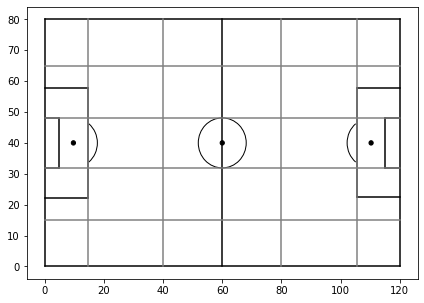

In [16]:
fig=plt.figure()
fig.set_size_inches(7, 5)
ax=fig.add_subplot(1,1,1)
draw_pitch(ax)
plt.show()

In [17]:
match = pd.read_csv('match_events.csv')

In [18]:
match.type.unique()

array(['Starting XI', 'Half Start', 'Pass', 'Ball Receipt*', 'Carry',
       'Pressure', 'Interception', 'Ball Recovery', 'Duel', 'Dribble',
       'Dribbled Past', 'Clearance', 'Dispossessed', 'Shot',
       'Goal Keeper', 'Miscontrol', 'Block', 'Injury Stoppage',
       'Foul Committed', 'Foul Won', '50/50', 'Referee Ball-Drop',
       'Half End', 'Substitution', 'Bad Behaviour', 'Tactical Shift'],
      dtype=object)

In [19]:
match_pass = match.loc[match['type']=='Pass']

In [20]:
match_pass_7 = match_pass.loc[match_pass['minute']==7]

In [21]:
match_pass_7

,index,id,duration,match_id,minute,pass_angle,pass_height,pass_length,pass_outcome,pass_recipient,...,team,timestamp,type,location_x,location_y,pass_end_location_x,pass_end_location_y,shot_end_location_x,shot_end_location_y,shot_end_location_z
105,347,3d004d9a-b072-4b52-b0de-a5af21a7462e,2.030071,3794687,7,-0.193211,High Pass,28.123300,Incomplete,Eden Hazard,...,Belgium,00:07:16.210,Pass,75.1,80.0,102.7,74.6,NaN,NaN,NaN
106,349,7dbaec56-465c-4d83-a0a6-7a0bf4fdfcbb,1.055530,3794687,7,-0.073263,High Pass,10.929318,NaN,Raphaël Adelino José Guerreiro,...,Portugal,00:07:18.240,Pass,17.4,5.5,28.3,4.7,NaN,NaN,NaN
107,351,7fa765ad-d5b3-49a0-bf47-63ca254223c7,0.803005,3794687,7,3.062394,High Pass,12.639620,NaN,Rúben Santos Gato Alves Dias,...,Portugal,00:07:19.295,Pass,28.3,4.7,15.7,5.7,NaN,NaN,NaN
108,353,b1f8288d-9fe8-4972-b26f-4f4a3ddcbb66,3.407518,3794687,7,0.083887,High Pass,33.417510,Incomplete,Diogo José Teixeira da Silva,...,Portugal,00:07:20.098,Pass,15.7,5.9,49.0,8.7,NaN,NaN,NaN
109,355,2314ab38-a613-4f83-917f-81c533f411a5,0.730643,3794687,7,-0.303571,Low Pass,8.697700,Incomplete,Kevin De Bruyne,...,Belgium,00:07:23.506,Pass,71.1,71.4,79.4,68.8,NaN,NaN,NaN
110,357,833bc05c-4416-4a95-9b90-9226c4f38bdd,0.979162,3794687,7,-0.881872,Low Pass,4.404543,NaN,Diogo José Teixeira da Silva,...,Portugal,00:07:24.237,Pass,40.7,11.3,43.5,7.9,NaN,NaN,NaN
111,359,9c052c25-f9c8-42ef-a6b0-b25e5b30b9c9,0.604712,3794687,7,1.477320,Ground Pass,6.428063,NaN,Renato Júnior Luz Sanches,...,Portugal,00:07:25.216,Pass,43.5,7.9,44.1,14.3,NaN,NaN,NaN
112,365,f5990b4e-e8ce-46c3-a4f8-81d7fc5cd62d,1.505122,3794687,7,2.699219,Ground Pass,12.614278,NaN,Toby Alderweireld,...,Belgium,00:07:27.395,Pass,69.6,64.7,58.2,70.1,NaN,NaN,NaN
113,368,e4d9013e-562f-465b-a915-865de0c3866d,1.177315,3794687,7,-1.825732,Ground Pass,17.051100,NaN,Thomas Vermaelen,...,Belgium,00:07:32.853,Pass,37.9,69.7,33.6,53.2,NaN,NaN,NaN
114,371,096050a8-174b-49dd-a7db-e9472f658c21,1.235939,3794687,7,1.146602,Ground Pass,13.605881,NaN,Toby Alderweireld,...,Belgium,00:07:36.804,Pass,33.2,51.9,38.8,64.3,NaN,NaN,NaN


In [22]:
def draw_players(match,team1,team2):
    # size of the pitch is 120, 80
    fig=plt.figure()
    fig.set_size_inches(7, 5)
    ax=fig.add_subplot(1,1,1)
    draw_pitch(ax)
    for x in range (0,len(match)):
        one = match[x:x+1]
        if one['team'].values==team1:
            plt.plot(one['location_x'],one['location_y'], marker="o", markersize=10, markeredgecolor="red", markerfacecolor="red")
        if one['team'].values==team2:
            plt.plot(one['location_x'],one['location_y'], marker="o", markersize=10, markeredgecolor="blue", markerfacecolor="blue") 

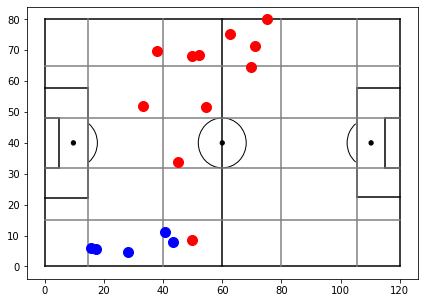

In [23]:
draw_players(match_pass_7,'Belgium','Portugal')


In [24]:
def draw_players_pass(match,team1,team2):
    fig, ax = plt.subplots()
    fig.set_size_inches(7, 5)
    
    for i in range(len(match)):
        if match['team'].iloc[i]==team1:
            plt.plot([int(match["location_x"].iloc[i]),int(match["pass_end_location_x"].iloc[i])],
                     [int(match["location_y"].iloc[i]),int(match["pass_end_location_y"].iloc[i])], 
                     color="red")
        if match['team'].iloc[i]==team2:
            plt.plot([int(match["location_x"].iloc[i]),int(match["pass_end_location_x"].iloc[i])],
                     [int(match["location_y"].iloc[i]),int(match["pass_end_location_y"].iloc[i])], 
                     color="blue")

        plt.plot(int(match["location_x"].iloc[i]),int(match["location_y"].iloc[i]),"o", color="green")

    draw_pitch(ax)
    plt.show()

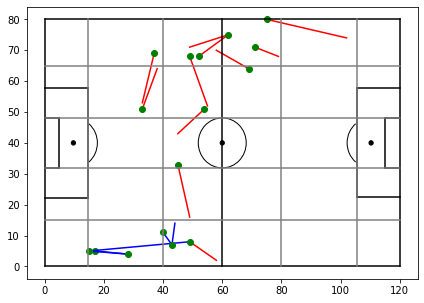

In [25]:
draw_players_pass(match_pass_7,'Belgium','Portugal')

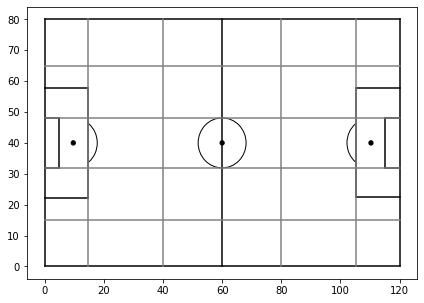

In [58]:
# plotting 3 events before shot
# not done
fig, ax = plt.subplots()
fig.set_size_inches(7, 5)
for i in range (3, len(match)):
    if match['type'].iloc[i]=='Shot':
        if match['type'].iloc[i-3]=='Pass':
            if match['team'].iloc[i-3]=='Belgium':
                plt.plot([int(match["location_x"].iloc[i-3]),int(match["pass_end_location_x"].iloc[i-3])],
                         [int(match["location_y"].iloc[i-3]),int(match["pass_end_location_y"].iloc[i-3])], 
                         color="red")
            if match['team'].iloc[i-3]=='Portugal':
                plt.plot([int(match["location_x"].iloc[i-3]),int(match["pass_end_location_x"].iloc[i-3])],
                         [int(match["location_y"].iloc[i-3]),int(match["pass_end_location_y"].iloc[i-3])], 
                         color="blue")

            plt.plot(int(match["location_x"].iloc[i]),int(match["location_y"].iloc[i]),"o", color="green")
draw_pitch(ax)
plt.show()